In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

from time import time

torch.manual_seed(42)

# Seleccionar GPU o CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch: 2.8.0+cu128
CUDA: 12.8
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
VRAM: 8.0 GB


In [2]:
a = torch.rand(1000, 1000).to(device)
b = torch.rand(1000, 1000).to(device)

c = a @ b

print("Resultado:", c.shape)
print("Dispositivo utilizado:", c.device)

Resultado: torch.Size([1000, 1000])
Dispositivo utilizado: cuda:0


In [3]:
def LoadDataset(folder, ext):

    nclasses = 0
    nperclass = []
    classlabels = []

    X = []
    Y = []

    # Cada subcarpeta se corresponde con una clase
    for class_name in sorted(os.listdir(folder)):

        class_folder = os.path.join(folder, class_name)

        if not os.path.isdir(class_folder):
            continue

        nclasses += 1
        nsamples = 0

        for file_name in os.listdir(class_folder):

            if file_name.lower().endswith(ext):

                # Lee la imagen en escala de grises
                gray = cv2.imread(
                    os.path.join(class_folder, file_name),
                    cv2.IMREAD_GRAYSCALE
                )

                if gray is None:
                    continue

                gray = cv2.resize(gray, (48, 48))

                # Añade la imagen convertida en vector
                X.append(gray.reshape(48 * 48))

                # Añade etiqueta numerica
                Y.append(nclasses - 1)

                nsamples += 1

        nperclass.append(nsamples)
        classlabels.append(class_name)

    return X, Y, nperclass, classlabels

In [4]:
folder_train = "FER2013/train"
folder_test = "FER2013/test"

ext = (".jpg", ".jpeg", ".png")

print("Cargando entrenamiento...")

X_train, y_train, nperclass_train, class_names = LoadDataset(
    folder_train, ext
)

print("Cargando test...")

X_test, y_test, nperclass_test, class_names_test = LoadDataset(
    folder_test, ext
)

assert class_names == class_names_test

# Convertir a arrays de NumPy
X_train = np.array(X_train, dtype="uint8")
X_test = np.array(X_test, dtype="uint8")

y_train = np.array(y_train)
y_test = np.array(y_test)

# Separar entrenamiento y validacion
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# Recuperar las dimensiones de las imagenes y normalizar
X_train = torch.tensor(X_train).reshape(-1, 1, 48, 48).float() / 255
X_val = torch.tensor(X_val).reshape(-1, 1, 48, 48).float() / 255
X_test = torch.tensor(X_test).reshape(-1, 1, 48, 48).float() / 255

# Convertir las etiquetas a tensores
y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Entrenamiento:", X_train.shape)
print("Validacion:", X_val.shape)
print("Test:", X_test.shape)
print("Clases:", class_names)

Cargando entrenamiento...
Cargando test...
Entrenamiento: torch.Size([24402, 1, 48, 48])
Validacion: torch.Size([4307, 1, 48, 48])
Test: torch.Size([7178, 1, 48, 48])
Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [5]:
batch_size = 128

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

print("Batches de entrenamiento:", len(train_loader))
print("Batches de validacion:", len(val_loader))
print("Batches de test:", len(test_loader))

Batches de entrenamiento: 191
Batches de validacion: 34
Batches de test: 57


In [6]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.red = nn.Sequential(

            # Primer bloque convolucional
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Segundo bloque convolucional
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Tercer bloque convolucional
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Clasificacion
            nn.Flatten(),

            nn.Linear(128 * 6 * 6, 128),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(128, 7)
        )

    def forward(self, x):
        return self.red(x)


modelo_cnn = CNN().to(device)

print(modelo_cnn)
print("Dispositivo:", next(modelo_cnn.parameters()).device)

CNN(
  (red): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=4608, out_features=128, bias=True)
    (11): ReLU()
    (12): Dropout(p=0.5, inplace=False)
    (13): Linear(in_features=128, out_features=7, bias=True)
  )
)
Dispositivo: cuda:0


In [7]:
criterio = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    modelo_cnn.parameters(),
    lr=0.001
)

epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

mejor_val_loss = float("inf")
mejores_pesos = None

patience = 4
sin_mejora = 0

t0 = time()

for epoch in range(epochs):

    # ENTRENAMIENTO
    modelo_cnn.train()

    loss_total = 0
    correctos = 0

    for images, labels in train_loader:

        # Enviar datos a la GPU
        images = images.to(device)
        labels = labels.to(device)

        # Limpiar gradientes
        optimizer.zero_grad()

        # Prediccion
        outputs = modelo_cnn(images)

        # Calcular error
        loss = criterio(outputs, labels)

        # Retropropagacion
        loss.backward()

        # Actualizar pesos
        optimizer.step()

        loss_total += loss.item() * labels.size(0)

        pred = outputs.argmax(dim=1)
        correctos += (pred == labels).sum().item()

    train_loss = loss_total / len(train_dataset)
    train_acc = correctos / len(train_dataset)

    # VALIDACION
    modelo_cnn.eval()

    loss_total = 0
    correctos = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = modelo_cnn(images)

            loss = criterio(outputs, labels)

            loss_total += loss.item() * labels.size(0)

            pred = outputs.argmax(dim=1)
            correctos += (pred == labels).sum().item()

    val_loss = loss_total / len(val_dataset)
    val_acc = correctos / len(val_dataset)

    # Guardar resultados
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f}"
    )

    # Early Stopping
    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss

        mejores_pesos = {
            k: v.detach().cpu().clone()
            for k, v in modelo_cnn.state_dict().items()
        }

        sin_mejora = 0

    else:

        sin_mejora += 1

        if sin_mejora >= patience:
            print("Early Stopping")
            break

# Recuperar el mejor modelo
modelo_cnn.load_state_dict(mejores_pesos)
modelo_cnn.eval()

tiempo_entrenamiento = time() - t0

print("Entrenamiento finalizado")
print("Tiempo:", round(tiempo_entrenamiento, 2), "segundos")

Epoch 1/20 | Train loss: 1.7799 | Train acc: 0.2704 | Val loss: 1.6836 | Val acc: 0.3109
Epoch 2/20 | Train loss: 1.6266 | Train acc: 0.3633 | Val loss: 1.5654 | Val acc: 0.3959
Epoch 3/20 | Train loss: 1.5256 | Train acc: 0.4141 | Val loss: 1.4547 | Val acc: 0.4409
Epoch 4/20 | Train loss: 1.4435 | Train acc: 0.4463 | Val loss: 1.3926 | Val acc: 0.4671
Epoch 5/20 | Train loss: 1.3821 | Train acc: 0.4677 | Val loss: 1.3285 | Val acc: 0.4897
Epoch 6/20 | Train loss: 1.3253 | Train acc: 0.4970 | Val loss: 1.2913 | Val acc: 0.5080
Epoch 7/20 | Train loss: 1.2822 | Train acc: 0.5170 | Val loss: 1.2944 | Val acc: 0.4955
Epoch 8/20 | Train loss: 1.2353 | Train acc: 0.5289 | Val loss: 1.2436 | Val acc: 0.5264
Epoch 9/20 | Train loss: 1.1992 | Train acc: 0.5429 | Val loss: 1.2384 | Val acc: 0.5268
Epoch 10/20 | Train loss: 1.1589 | Train acc: 0.5598 | Val loss: 1.2223 | Val acc: 0.5407
Epoch 11/20 | Train loss: 1.1247 | Train acc: 0.5717 | Val loss: 1.2206 | Val acc: 0.5421
Epoch 12/20 | Train

In [8]:
torch.save(
    {
        "model_state_dict": modelo_cnn.state_dict(),
        "class_names": [str(c) for c in class_names],
        "image_size": (48, 48)
    },
    "modelo_cnn.pth"
)

print("Modelo CNN guardado correctamente")

Modelo CNN guardado correctamente


In [9]:
modelo_cnn.eval()

y_pred = []
y_real = []

if device.type == "cuda":
    torch.cuda.synchronize()

t0 = time()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = modelo_cnn(images)

        pred = outputs.argmax(dim=1)

        y_pred.extend(pred.cpu().numpy())
        y_real.extend(labels.numpy())

if device.type == "cuda":
    torch.cuda.synchronize()

tiempo_prediccion = time() - t0

print("Accuracy:", accuracy_score(y_real, y_pred) * 100, "%")
print("Tiempo de prediccion:", tiempo_prediccion, "s")

print(classification_report(
    y_real,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

Accuracy: 55.266090833101146 %
Tiempo de prediccion: 0.5595324039459229 s
              precision    recall  f1-score   support

       angry       0.46      0.45      0.45       958
     disgust       0.81      0.15      0.26       111
        fear       0.40      0.30      0.34      1024
       happy       0.76      0.77      0.76      1774
     neutral       0.49      0.55      0.52      1233
         sad       0.41      0.47      0.44      1247
    surprise       0.72      0.69      0.70       831

    accuracy                           0.55      7178
   macro avg       0.58      0.48      0.50      7178
weighted avg       0.56      0.55      0.55      7178



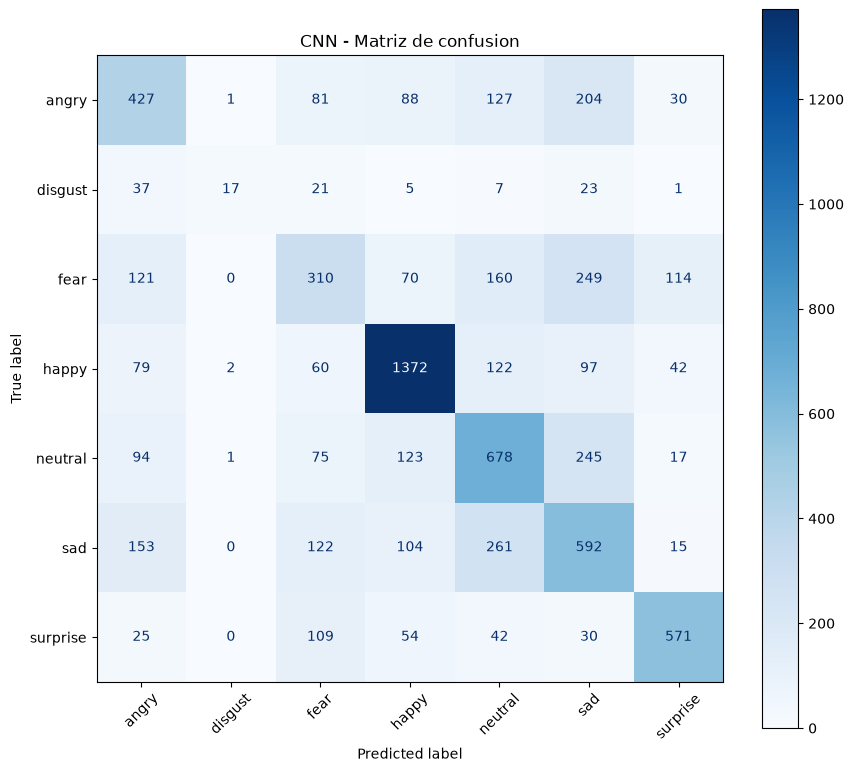

In [10]:
cm = confusion_matrix(
    y_real, y_pred,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN - Matriz de confusion")
plt.tight_layout()
plt.savefig("matriz_confusion_cnn.png", dpi=150)
plt.show()